In [749]:
from pathlib import Path 
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import(

 accuracy_score  ,confusion_matrix , ConfusionMatrixDisplay,
 f1_score

)
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model  import LogisticRegression

In [750]:
 

# Initialize the generator (optionally pass a seed for reproducibility)
# rng = np.random.default_rng(seed=42)
# np.random.seed(RANDOM_STATE)
# rng = np.random.default_rng(seed=RANDOM_STATE)

In [751]:
RANDOM_STATE=24


NOISE=0.6
EPOCHES=20001
ALPHA= 0.00001
N_SAMPLE= 1000
TEST_SIZE=0.2

dim_h_layer = 4

RANDOM_STATE=24 

# Initialize the generator (optionally pass a seed for reproducibility)
rng = np.random.default_rng(seed=RANDOM_STATE)
param = {
    'legend.fontsize': 'medium',
    'figure.figsize' : (15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium',

}

plt.rcParams.update(param)

CMAP  = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [752]:
X,y= datasets.make_moons(n_samples=N_SAMPLE,shuffle= True, noise=NOISE,random_state=RANDOM_STATE)
X[:5],y[:5]
                       

(array([[ 1.36153263,  1.23927688],
        [-2.12317806,  0.68483322],
        [ 1.67451886,  0.46643807],
        [-0.82128228, -0.35759026],
        [-0.90872252,  0.09119871]]),
 array([0, 0, 1, 0, 0]))

In [753]:
Data_df= pd.DataFrame(X,columns=['A','B'])
Data_df['Target'] = y  # ADD TO THE dATAfRAME
Data_df.sample(5)

# Data_df.describe(),Data_df.isnull(),Data_df.info()
# Data_df.Target.unique()

,A,B,Target
912,0.660583,0.245993,1
97,0.671169,0.137926,1
491,0.703070,0.094612,1
930,1.046619,-0.280990,1
502,0.332775,-0.948940,1


<Axes: xlabel='Target'>

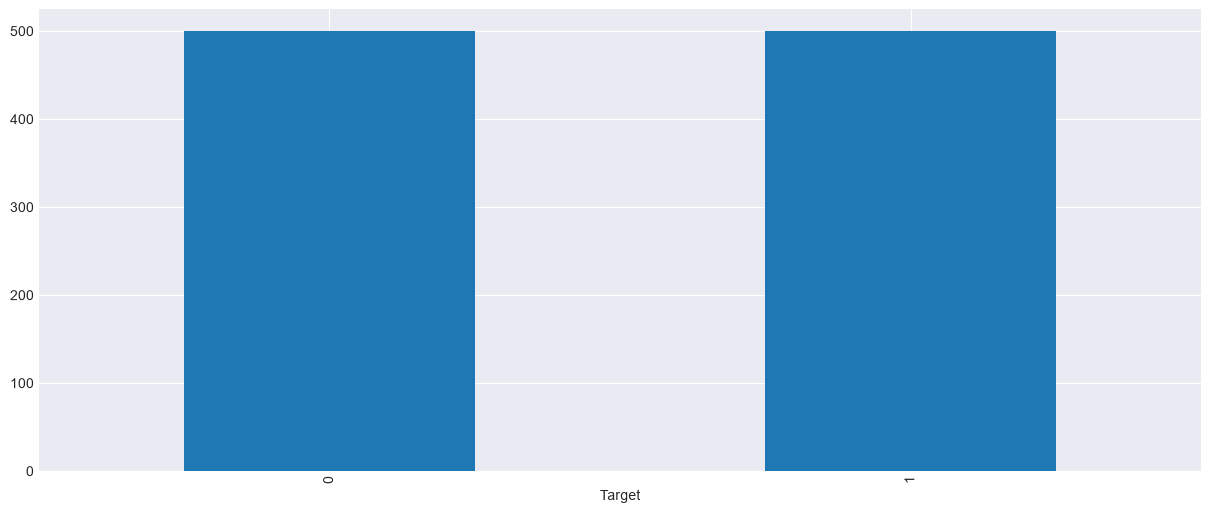

In [754]:
fig , ax= plt.subplots()
Data_df['Target'].value_counts().plot(ax=ax,kind='bar')

In [755]:
# 3.Load Dataset 

X_train, X_test, y_train, y_test = train_test_split( X, y, 
                                                    test_size=TEST_SIZE, 
                                                    random_state=RANDOM_STATE,
                                                    stratify=y)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(800, 2) (200, 2) (800,) (200,)


### Different plots

In [756]:
# Data_df.plot.scatter('A','B',s=40,marker='*' , c = 'Target',cmap= 'coolwarm')

In [757]:
data_train, data_test = Data_df.to_numpy()[:900], Data_df.to_numpy()[900:]
data_train.shape, data_test.shape

((900, 3), (100, 3))

# Activation Function 

1. sigmoid

In [758]:
def fn_sigmoid(z):
    return 1 / (1+np.exp(-z))

In [759]:
fn_sigmoid(np.asarray([-np.inf,-1,0,+1,np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

2. Tanh Activation Function

In [760]:
def fn_activ(z: np.ndarray) -> np.ndarray:
    return np.tanh(z)

def fn_activ_prime(z: np.ndarray) -> np.ndarray:
    return 1.0 - np.tanh(z)**2

In [761]:
fn_activ(np.asarray([[-1,0,-1], [-np.inf, 0 , +np.inf]]))

array([[-0.76159416,  0.        , -0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [762]:
def fn_predict(model:dict , X_p: np.ndarray):
    '''
    model : Dictionary containing weights and bias
    X: input features 
    '''

    W1 , W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']

    ## Forward Propogation
    # Layer 1
    z1 = X_p.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1) # Activation

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggregation
    a2 = fn_sigmoid(z2) 
    
    return a2 >= 0.5

In [763]:
def fn_calculate_loss(model : dict, X_l: np.ndarray, y_l: np.ndarray):
    ''' 
    model : Dictionary containing weights and bias
    X_l : input features
    y_l : targets
    '''

    m = X_l.shape[0]
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']

    # Forward propagation
    # Layer 1
    z1 = X_l.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1) # Activation

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggregation
    a2 = fn_sigmoid(z2)
    data_loss = -(y_l * np.log(a2) + (1 - y_l ) * np.log(1 - a2)).sum()
     
    return data_loss / m


In [764]:

# weights = np.array([0.1, 2.0, 1.0])
# display(Data_df.loc[0])
# predict(Data_df.loc[0].values, weights)



In [765]:


def fu_build_model(
        nn_hdim: np.int64,
        X: np.ndarray,
        y: np.ndarray,
        alpha: np.float64 = np.float64(ALPHA),
        n_epochs: np.int64 = EPOCHES 
        ) -> dict:
    ''' 
        nn_hdim: Number of hidden units,
        X:  Features,
        y:  Labels,
        alpha: Learning rate,
        n_epochs: number of passes through complete data for gradient descent 
    '''

    m, nn_input_dim = X.shape
    nn_output_dim = y.shape[1]

    W1 = rng.random((nn_input_dim, nn_hdim), dtype=np.float32) / np.sqrt(nn_input_dim)
    W2 = rng.random((nn_hdim, nn_output_dim), dtype=np.float32) / np.sqrt(nn_hdim)

    b1 = np.zeros((1, nn_hdim), dtype=np.float32)
    b2 = np.zeros((1, nn_output_dim), dtype=np.float32)

    curr_loss = 0
    loss, epoch = [], [] # collect loss and epoch

    for i in range(n_epochs): # loop for number of epochs
        ## Forward Propagation
        # Layer 1
        z1 = X.dot(W1) + b1 # Aggregation
        a1 = fn_activ(z1) # Activation
    
        # Layer 2
        z2 = a1.dot(W2) + b2 # Aggregation
        a2 = fn_sigmoid(z2)  # Activation

        ### Back Propagation 
        # Layer 2
        dz2 = a2 - y 
        dw2 = (a1.T).dot(dz2)

        assert W2.shape == dw2.shape, f'Shape- W2:{W2.shape} | dw2: {dw2.shape}'
        db2 = np.sum(dz2, axis=0, keepdims=True)
        assert b2.shape == db2.shape, f'Shape- b2:{b2.shape} | db2: {db2.shape}'
         
        da1 = dz2.dot(W2.T)
        assert a1.shape == da1.shape, f'Shape- a1:{a1.shape} | da1: {da1.shape}'

        # Layer 1
        dz1 = da1 * fn_activ_prime(z1)
        dw1 = (X.T).dot(dz1)
        
        # FIXED: check dw1 instead of dw2
        assert W1.shape == dw1.shape, f'Shape- W1:{W1.shape} | dw1: {dw1.shape}'
        db1 = np.sum(dz1, axis=0, keepdims=True)
        assert b1.shape == db1.shape, f'Shape- b1:{b1.shape} | db1: {db1.shape}'

        # Gradient Updates
        W1 = W1 - alpha * dw1 / m 
        W2 = W2 - alpha * dw2 / m 
        b1 = b1 - alpha * db1 / m 
        b2 = b2 - alpha * db2 / m 

        model = {"W1": W1, "W2": W2, 'b1': b1, 'b2': b2}

        if i % 100 == 0:
            curr_loss = fn_calculate_loss(model=model, X_l=X, y_l=y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f"Epoch {i:3d}: Loss = {curr_loss:.4f}")

    loss_hist['epoch'] = epoch 
    loss_hist['loss'] = loss

    return model



In [766]:
loss_hist = {}
y_train = y_train.reshape(-1,1)

model = fu_build_model(
        dim_h_layer,
        X_train,
        y_train )

Epoch   0: Loss = 0.7072
Epoch 100: Loss = 0.7072


Epoch 200: Loss = 0.7072
Epoch 300: Loss = 0.7071
Epoch 400: Loss = 0.7071
Epoch 500: Loss = 0.7071
Epoch 600: Loss = 0.7070
Epoch 700: Loss = 0.7070
Epoch 800: Loss = 0.7070
Epoch 900: Loss = 0.7069
Epoch 1000: Loss = 0.7069
Epoch 1100: Loss = 0.7069
Epoch 1200: Loss = 0.7068
Epoch 1300: Loss = 0.7068
Epoch 1400: Loss = 0.7068
Epoch 1500: Loss = 0.7067
Epoch 1600: Loss = 0.7067
Epoch 1700: Loss = 0.7067
Epoch 1800: Loss = 0.7066
Epoch 1900: Loss = 0.7066
Epoch 2000: Loss = 0.7066
Epoch 2100: Loss = 0.7065
Epoch 2200: Loss = 0.7065
Epoch 2300: Loss = 0.7065
Epoch 2400: Loss = 0.7064
Epoch 2500: Loss = 0.7064
Epoch 2600: Loss = 0.7064
Epoch 2700: Loss = 0.7063
Epoch 2800: Loss = 0.7063
Epoch 2900: Loss = 0.7063
Epoch 3000: Loss = 0.7062
Epoch 3100: Loss = 0.7062
Epoch 3200: Loss = 0.7062
Epoch 3300: Loss = 0.7061
Epoch 3400: Loss = 0.7061
Epoch 3500: Loss = 0.7061
Epoch 3600: Loss = 0.7060
Epoch 3700: Loss = 0.7060
Epoch 3800: Loss = 0.7060
Epoch 3900: Loss = 0.7060
Epoch 4000: Loss = 0

<Axes: xlabel='epoch'>

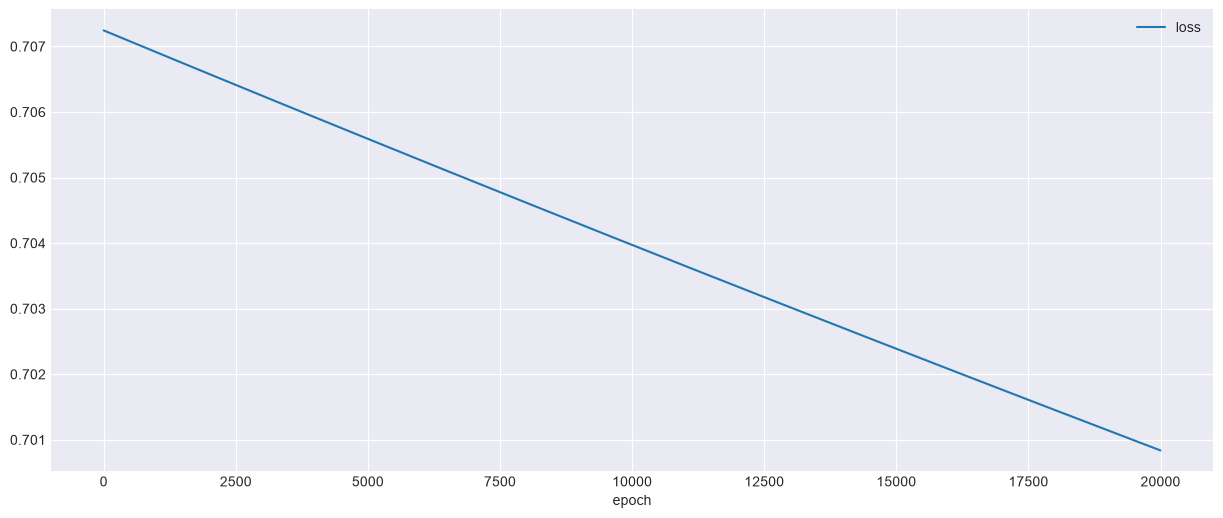

In [767]:
loss_df = pd.DataFrame(loss_hist)

fig , ax = plt.subplots()

loss_df.plot(x='epoch',y='loss' , ax=ax) 

In [768]:
y_pred = fn_predict(model = model, X_p = X_train)

f_score = f1_score(y_train, y_pred , average='weighted')
f_score

0.48609347249992196

[[116 284]
 [107 293]]


Text(0.5, 1.0, 'F1 Score: 0.48609347249992196')

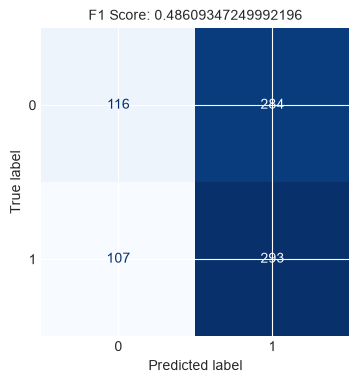

In [769]:

cm = confusion_matrix(y_train , y_pred) 
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
 
fig , ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'F1 Score: {f_score}')
 


In [770]:
y_pred = fn_predict(model = model, X_p = X_test)
f_score = f1_score(y_test, y_pred , average='weighted')

f_score


0.5469744364146263

[[31 69]
 [15 85]]


Text(0.5, 1.0, 'F1 Score: 0.5469744364146263')

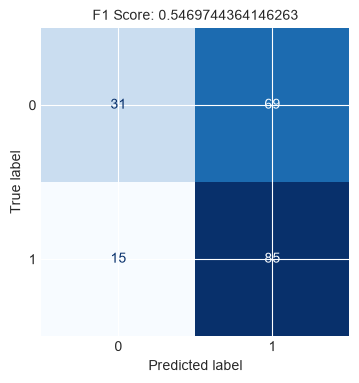

In [771]:
y_pred = fn_predict(model = model, X_p = X_test)
accuracy_score(y_test, y_pred)

cm = confusion_matrix(y_test , y_pred) 
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
 
fig , ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'F1 Score: {f_score}')


# Helper Function

In [772]:
# Helper function

In [773]:
def plot_decision_boundary(model:dict ,
                           X_tr :np.ndarray ,
                           y_tr:np.ndarray ,
                           X_ts:np.ndarray ,
                           y_ts :np.ndarray ,
                             ):
    
    fig , ax = plt.subplots()
    dm = 0.01
    margin = 10*dm
    xMin = min( X_tr[:, 0].min() - margin, X_ts[:, 0].min() - margin)
    xMax = min( X_tr[:, 0].max() + margin, X_ts[:, 0].max() + margin)
    yMin = min( X_tr[:, 1].min() - margin, X_ts[:, 1].min() - margin)
    yMax = min( X_tr[:, 1].max() + margin, X_ts[:, 1].max() + margin)

 
    xx,yy = np.meshgrid(np.arange(xMin , xMax, dm),
                        np.arange(yMin , yMax, dm))
    
    XX = np.c_[xx.ravel(), yy.ravel()]

    Z = fn_predict(model, XX).reshape(xx.shape)

    ax.contourf(xx,yy , Z, cmap= plt.cm.Paired , alpha = 0.6)
    ax.scatter(X_tr[:,0], X_tr[:,1], c=y_tr,
                s =30 , edgecolors='k', cmap= CMAP)
    ax.scatter(X_ts[:,0], X_ts[:,1], c=y_ts,
                    s =30 ,marker='*', edgecolors='k', cmap= plt.cm.seismic)

    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()

C:\Users\RAJESH\AppData\Local\Temp\ipykernel_21620\2729854710.py:33: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


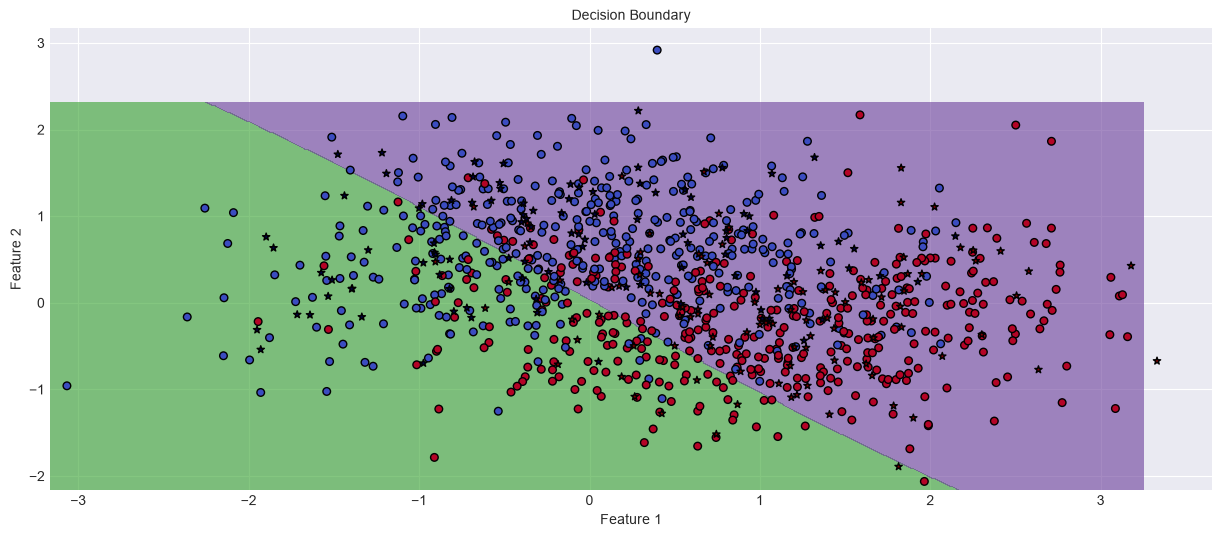

In [774]:
plot_decision_boundary(model = model, X_tr = X_train,y_tr = y_train, X_ts= X_test,y_ts = y_test)